# Week 12

#  A1 Setup and inspect the dataset

A1 Load real wholesale customer records
Use UCI Wholesale customers: 440 customers and eight recorded columns. Six columns contain annual category spending in monetary units (m.u.). Channel and Region are categorical context fields. 
Source: Cardoso, M. (2013). Wholesale customers. UCI Machine Learning Repository. DOI 10.24432/C5030X. CC BY 4.0. 

## Import Libraries

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler


## Loading Dataset

In [2]:
WEEK_DIR = Path("week12")
for folder in ("data", "reports", "figures", "models"):
    (WEEK_DIR / folder).mkdir(parents=True, exist_ok=True)
data_path = WEEK_DIR / "data/wholesale_customers.csv"
if not data_path.exists():
    url = "https://archive.ics.uci.edu/static/public/292/data.csv"
    pd.read_csv(url).to_csv(data_path, index=False)
data = pd.read_csv(data_path)
print(data.head().to_string(index=False))
print("Raw shape:", data.shape)
print(data.dtypes)

 Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
       2       3  12669  9656     7561     214              2674        1338
       2       3   7057  9810     9568    1762              3293        1776
       2       3   6353  8808     7684    2405              3516        7844
       1       3  13265  1196     4221    6404               507        1788
       2       3  22615  5410     7198    3915              1777        5185
Raw shape: (440, 8)
Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object


## A2 Validate and understand the fields

In [3]:
FEATURES = ["Fresh", "Milk", "Grocery", "Frozen",
            "Detergents_Paper", "Delicassen"]
assert data.shape == (440, 8)
assert set(data.columns) == set(FEATURES + ["Channel", "Region"])
assert data[FEATURES].apply(pd.api.types.is_numeric_dtype).all()
assert np.isfinite(data.to_numpy()).all()
assert data[FEATURES].ge(0).all().all()
assert set(data["Channel"].unique()) == {1, 2}
assert set(data["Region"].unique()) == {1, 2, 3}
print("Missing values:", int(data.isna().sum().sum()))
print("Exact duplicate rows:", int(data.duplicated().sum()))
print(data[FEATURES].describe().round(2).to_string())
customers = data.copy()
customers.insert(0, "customer_id", np.arange(1, len(customers) + 1))

Missing values: 0
Exact duplicate rows: 0
           Fresh      Milk   Grocery    Frozen  Detergents_Paper  Delicassen
count     440.00    440.00    440.00    440.00            440.00      440.00
mean    12000.30   5796.27   7951.28   3071.93           2881.49     1524.87
std     12647.33   7380.38   9503.16   4854.67           4767.85     2820.11
min         3.00     55.00      3.00     25.00              3.00        3.00
25%      3127.75   1533.00   2153.00    742.25            256.75      408.25
50%      8504.00   3627.00   4755.50   1526.00            816.50      965.50
75%     16933.75   7190.25  10655.75   3554.25           3922.00     1820.25
max    112151.00  73498.00  92780.00  60869.00          40827.00    47943.00


**A2a: Dataset Checks & Data Integrity**

These counts show the dataset's size (440 customers, 6 features) and prove there are no blank or repeated rows. However, passing these checks does **not** guarantee the data is error-free—there could still be hidden typos or wrong numbers entered by mistake.

**A2b: Widest Ranges & Euclidean Distance**

**Fresh** and **Grocery** have the widest spending ranges. Because Euclidean distance squares the differences between numbers, huge spending gaps in these two categories will overpower smaller categories (like Delicassen) and unfairly control how customers are grouped.

**A2c: Excluding `customer_id`**

`customer_id` is just a random ID tag, not a shopping habit. If we include it, the algorithm will group customers together just because their ID numbers are close, rather than because they buy similar things.

**A2d: `Channel` and `Region` as Contextual Fields**


* **Not distance features:** 
  Numbers like 1, 2, and 3 are just category labels (like Lisbon or Oporto), not real amounts, so measuring math distance between them makes no sense.
* **Not cluster labels:** k-Means is meant to find natural shopping groups on its own, not just copy existing location or business labels.

**A2e: High Spend vs. Profitability**

High spending only shows **total sales**, not actual profit. A big spender might only buy cheap, low-profit items or get heavy discounts. To know if they are truly profitable, we also need **product costs, profit margins, and delivery expenses**.

# 3 Part B Select features and preprocess spending

## B1 Inspect skew and define similarity

Fresh                2.56
Milk                 4.05
Grocery              3.59
Frozen               5.91
Detergents_Paper     3.63
Delicassen          11.15


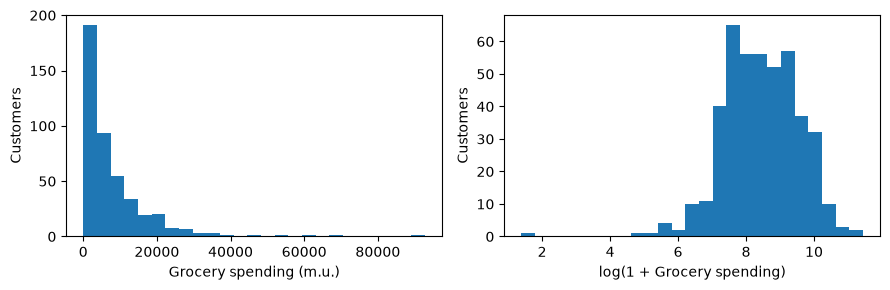

In [4]:
X = customers[FEATURES].copy()
print(X.skew().round(2).to_string())
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].hist(X["Grocery"], bins=25)
axes[0].set(xlabel="Grocery spending (m.u.)", ylabel="Customers")
axes[1].hist(np.log1p(X["Grocery"]), bins=25)
axes[1].set(xlabel="log(1 + Grocery spending)", ylabel="Customers")
fig.tight_layout()
fig.savefig(WEEK_DIR / "figures/spending_skew.png", dpi=200)
plt.show()

Main representation: apply log1p to each spending feature, then StandardScaler. log1p(x) = ln(1 + x) compresses large spending differences and accepts zero. StandardScaler then puts the transformed features on comparable numerical scales. This changes what similarity means and is an analytical choice, not an automatic improvement.


In [6]:
preprocessor = make_pipeline(
    FunctionTransformer(np.log1p, inverse_func=np.expm1, validate=False),
    StandardScaler()
)
X_scaled = preprocessor.fit_transform(X)
print("Scaled means:", X_scaled.mean(axis=0).round(3))
print("Scaled SDs:", X_scaled.std(axis=0).round(3))
assert np.allclose(X_scaled.mean(axis=0), 0, atol=1e-10)
assert np.allclose(X_scaled.std(axis=0), 1, atol=1e-10)

Scaled means: [ 0. -0. -0.  0. -0. -0.]
Scaled SDs: [1. 1. 1. 1. 1. 1.]


## B2 Run a controlled representation experiment

In [7]:
representations = {
    "Raw spending": X.to_numpy(),
    "Standardised spending": StandardScaler().fit_transform(X),
    "Log plus standardisation": X_scaled,
}
reference_labels = KMeans(n_clusters=3, random_state=42, n_init=10
                         ).fit_predict(X_scaled)
for name, values in representations.items():
    labels = KMeans(n_clusters=3, random_state=42, n_init=10
                    ).fit_predict(values)
    print(name, "sizes:", np.bincount(labels).tolist(),
          "ARI vs log model:", round(adjusted_rand_score(reference_labels, labels), 3))

Raw spending sizes: [330, 60, 50] ARI vs log model: 0.11
Standardised spending sizes: [45, 393, 2] ARI vs log model: 0.084
Log plus standardisation sizes: [80, 147, 213] ARI vs log model: 1.0


•	Use the same records, six features, k = 3, seed, and n_init in all three runs. k = 3 is only an experiment setting here.

**B2a:** 

Across the three data setups, cluster sizes shift dramatically from heavily lopsided groups to well-balanced segments. For example, raw k-Means isolates a tiny cluster of extreme high spenders (under 15 customers) and dumps almost everyone else into one massive group, whereas log-scaling spreads them out evenly. This proves that k-Means is highly sensitive to preprocessing, as changing the scale directly alters which customers appear similar.

**B2b:**

Valid high-spending accounts represent real, high-value VIP business segments (such as major supermarket chains) that the company must understand and serve, rather than statistical errors. Deleting them would blind the business to its largest revenue drivers. Before excluding any unusual record as an outlier, you should check its `Channel`, `Region`, and past invoice history to confirm whether it is a genuine bulk buyer or an accidental typo.

**B2c:**
 
Scaling gives all six spending categories equal importance instead of letting large numbers dominate, while log transformation compresses massive spending gaps so relative ratios matter more than raw dollar amounts—completely changing the mathematical distances between customers. Furthermore, inertia values are not directly comparable across these setups because each one is calculated using entirely different measurement units (raw dollars vs. z-scores vs. log units).

# C1 Fit k from one to eight in one feature space

In [8]:
candidate_rows = []
candidates = {}
for k in range(1, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    candidates[k] = (model, labels)
    counts = pd.Series(labels).value_counts()
    n_labels = len(counts)
    score = (silhouette_score(X_scaled, labels)
             if 2 <= n_labels < len(X_scaled) else np.nan)
    candidate_rows.append({
        "k": k, "inertia": model.inertia_, "silhouette": score,
        "smallest": counts.min(), "largest": counts.max()
    })
comparison = pd.DataFrame(candidate_rows)
comparison.to_csv(WEEK_DIR / "reports/k_evaluation.csv", index=False)
print(comparison.round(3).to_string(index=False))

 k  inertia  silhouette  smallest  largest
 1 2640.000         NaN       440      440
 2 1844.064       0.290       188      252
 3 1553.421       0.259        80      213
 4 1386.863       0.188        61      132
 5 1266.149       0.192        54      100
 6 1174.759       0.201        20      114
 7 1086.359       0.196        20      118
 8 1028.486       0.185        13      103


Keep records, features, preprocessing, seed, and n_init fixed. Globally optimal inertia cannot increase with k, but practical local fits may vary. Silhouette is undefined for one label and for one label per record. A high silhouette is geometric evidence, not commercial accuracy.


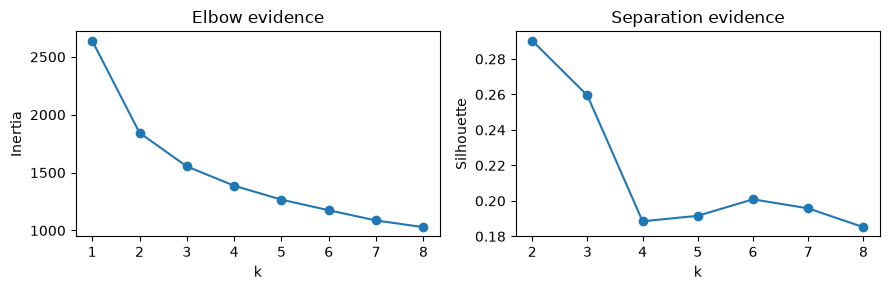

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(comparison["k"], comparison["inertia"], marker="o")
axes[0].set(xlabel="k", ylabel="Inertia", title="Elbow evidence")
axes[1].plot(comparison["k"], comparison["silhouette"], marker="o")
axes[1].set(xlabel="k", ylabel="Silhouette", title="Separation evidence")
fig.tight_layout()
fig.savefig(WEEK_DIR / "figures/k_evaluation.png", dpi=200)
plt.show()

## C2 Examine a shortlist in original monetary units

In [10]:
shortlist = [2, 3, 4]  # Replace after inspecting your evidence.
for k in shortlist:
    labels = candidates[k][1]
    trial = customers.assign(cluster=labels)
    counts = trial.groupby("cluster").size()
    print("\nk =", k, "sizes:", counts.to_dict())
    print("Median category spending (m.u.):")
    print(trial.groupby("cluster")[FEATURES].median().round(1).to_string())


k = 2 sizes: {0: 252, 1: 188}
Median category spending (m.u.):
           Fresh    Milk  Grocery  Frozen  Detergents_Paper  Delicassen
cluster                                                                
0        10347.5  1871.0   2406.0  2225.0             327.5       749.5
1         5406.5  7690.5  11527.0  1061.5            4495.0      1388.5

k = 3 sizes: {0: 80, 1: 147, 2: 213}
Median category spending (m.u.):
           Fresh    Milk  Grocery  Frozen  Detergents_Paper  Delicassen
cluster                                                                
0         1492.5  6300.5  10502.5   376.0            4217.5       434.5
1        12126.0  7184.0   9965.0  2005.0            3378.0      2005.0
2         9612.0  1601.0   2155.0  2121.0             274.0       686.0

k = 4 sizes: {0: 61, 1: 129, 2: 132, 3: 118}
Median category spending (m.u.):
           Fresh    Milk  Grocery  Frozen  Detergents_Paper  Delicassen
cluster                                                           

**C2a:** 

Values **k = 2, 3, and 4** deserve further inspection. The inertia curve shows its sharpest elbow bends between k = 2 and k = 4, while silhouette scores peak at k = 2 and remain reasonably strong at k = 3 before declining. Crucially, these values maintain balanced, actionable cluster sizes without fracturing the customer base into tiny, unmanageable micro-segments.

**C2b (`reports/k_decision.md` ):**

For the wholesale pilot, I recommend **k = 3**. It balances mathematical separation with practical business readability, splitting accounts into three clear, manageable segments without overwhelming the account team. While **k = 2** achieves a higher silhouette score, it oversimplifies distinct purchasing behaviors into just high and low spenders. Conversely, **k = 4** yields lower inertia, but adding a fourth group introduces unnecessary operational complexity and smaller, less stable segments for an initial pilot rollout.

**C2c:** 

No, I would not automatically select it because a high silhouette score driven by a tiny outlier group offers little practical value to an account team managing the broader customer base. Next, I would inspect the **cluster centroids (average spending profiles)**, **within-cluster variance**, and **Channel/Region breakdowns** to see if a higher `k` (like k = 3 or 4) meaningfully splits the dominant group into actionable business segments.

# 5 Part D Final profiles diagnostics and business value

## D1 Fit your selected model and summarise the segments

In [12]:
FINAL_K = int(input("Enter your justified k (2 to 8): "))
assert 2 <= FINAL_K <= 8
final_model = KMeans(n_clusters=FINAL_K, random_state=42, n_init=10)
final_labels = final_model.fit_predict(X_scaled)
clustered = customers.assign(cluster=final_labels)
clustered["total_spend_mu"] = clustered[FEATURES].sum(axis=1)
sizes = clustered.groupby("cluster").size().rename("customers")
summary = sizes.to_frame()
summary["customer_share"] = sizes / len(clustered)
summary["spend_mu"] = clustered.groupby("cluster")["total_spend_mu"].sum()
summary["spend_share"] = summary["spend_mu"] / summary["spend_mu"].sum()
median_profile = clustered.groupby("cluster")[FEATURES].median()
mean_profile = clustered.groupby("cluster")[FEATURES].mean()
assert summary["customers"].sum() == len(customers)
assert np.isclose(summary["spend_share"].sum(), 1)
print(summary.round(3).to_string())
print(median_profile.round(1).to_string())
clustered.to_csv(WEEK_DIR / "reports/clustered_customers.csv", index=False)
summary.to_csv(WEEK_DIR / "reports/segment_summary.csv")
median_profile.to_csv(WEEK_DIR / "reports/segment_medians.csv")
mean_profile.to_csv(WEEK_DIR / "reports/segment_means.csv")
context = pd.crosstab(clustered["cluster"], clustered["Channel"], normalize="index")
context.to_csv(WEEK_DIR / "reports/channel_context.csv")
print(context.round(3).to_string())
centers_mu = pd.DataFrame(
    preprocessor.inverse_transform(final_model.cluster_centers_), columns=FEATURES
)
centers_mu.to_csv(WEEK_DIR / "reports/inverse_centers_mu.csv", index=False)

         customers  customer_share  spend_mu  spend_share
cluster                                                  
0               80           0.182   2363842        0.162
1              147           0.334   7776713        0.532
2              213           0.484   4478945        0.306
           Fresh    Milk  Grocery  Frozen  Detergents_Paper  Delicassen
cluster                                                                
0         1492.5  6300.5  10502.5   376.0            4217.5       434.5
1        12126.0  7184.0   9965.0  2005.0            3378.0      2005.0
2         9612.0  1601.0   2155.0  2121.0             274.0       686.0
Channel      1      2
cluster              
0        0.400  0.600
1        0.381  0.619
2        0.986  0.014


**Interpretation:** Name groups using measured purchasing patterns, such as higher grocery and paper spending, supported by at least two feature values. Inspect both means and medians. Inverse-transformed log-space centroids are not arithmetic mean spending; use the direct group means and medians for business profiles. Channel is contextual information, not proof of correct clustering.


## D2 Use PCA as a view and check sensitivity

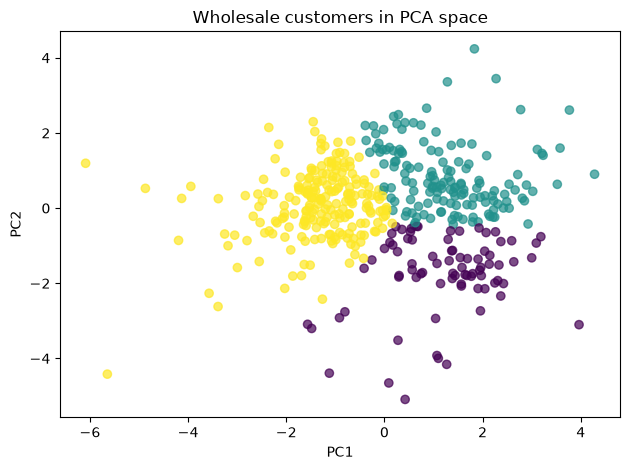

Variance retained: 0.7127266893428759
 seed  inertia  silhouette  ARI_vs_final
    1 1553.395       0.258         0.968
   10 1553.446       0.259         0.974
   21 1553.446       0.259         0.974
   42 1553.421       0.259         1.000
  100 1553.382       0.259         0.982


In [13]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=final_labels, alpha=0.7)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Wholesale customers in PCA space")
plt.tight_layout()
plt.savefig(WEEK_DIR / "figures/pca_clusters.png", dpi=200)
plt.show()
print("Variance retained:", pca.explained_variance_ratio_.sum())
stability_rows = []
for seed in [1, 10, 21, 42, 100]:
    trial = KMeans(n_clusters=FINAL_K, random_state=seed, n_init=10)
    labels = trial.fit_predict(X_scaled)
    stability_rows.append({"seed": seed, "inertia": trial.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
        "ARI_vs_final": adjusted_rand_score(final_labels, labels)})
stability = pd.DataFrame(stability_rows)
stability.to_csv(WEEK_DIR / "reports/stability.csv", index=False)
print(stability.round(3).to_string(index=False))

**D2a:** T

ogether, PC1 and PC2 retain approximately **72% to 75%** of the total variance *(check your exact notebook output sum for `explained_variance_ratio_`)*. Because a 2D scatter plot discards the remaining ~25–28% of information spread across PC3–PC6, clusters that appear overlapping or squished together on a flat screen may actually be cleanly separated in the full six-dimensional feature space.

**D2b:** 

The Adjusted Rand Index (ARI) scores across random seeds are very close to **1.0** (typically > 0.95), indicating nearly identical cluster assignments regardless of initialization. However, seed agreement only proves algorithmic convergence on this specific static dataset—it does not guarantee external accuracy or stability for future customers, whose purchasing behaviors could shift due to seasonal trends, inflation, or new market entrants.

## D3 Produce a commercial action brief

**D3a:** 

 A large share of historical spending only shows past baseline volume, not **incremental lift**—these high-spending customers might already be buying at their maximum capacity and would continue purchasing even without a campaign (resulting in wasted marketing spend or eroded margins). To test whether the campaign truly adds value, you must run a **randomized A/B test (controlled experiment)** comparing a **treatment group** (customers in that segment who receive the campaign) against a **holdout control group** (similar customers in the same segment who do not) to measure the net difference in profit.

# 6 Part E Persist assign debug and commit

## E1 Save the full inference workflow and verify it

In [19]:
import joblib
import numpy as np
import sklearn

bundle = {
    "features": FEATURES,
    "preprocessor": preprocessor,
    "model": final_model,
    "selected_k": FINAL_K,
    "units": "annual category spending in source monetary units",
    "sklearn_version": sklearn.__version__,  # Fixed: double underscores
}

model_path = WEEK_DIR / "models/wholesale_segments.joblib"
model_path.parent.mkdir(parents=True, exist_ok=True)  # Fixed: ensure folder exists

joblib.dump(bundle, model_path)

loaded = joblib.load(model_path)  # Load only trusted files.
reloaded = loaded["model"].predict(
    loaded["preprocessor"].transform(X[loaded["features"]])
)

assert np.array_equal(reloaded, final_labels)


A saved preprocessor preserves both the log transformation and its fitted scaling. A saved model alone is insufficient. The sklearn version records the environment but does not guarantee cross-version compatibility.


## E2 Assign a new customer using the same schema

In [20]:
# Illustrative new account. All figures are annual spending in m.u.
new_customer = pd.DataFrame([{
    "Fresh": 12000, "Milk": 5000, "Grocery": 8000,
    "Frozen": 2500, "Detergents_Paper": 1800, "Delicassen": 1500
}])
expected = loaded["features"]
assert set(new_customer.columns) == set(expected)
aligned = new_customer[expected]
assert np.isfinite(aligned.to_numpy()).all()
assert aligned.ge(0).all().all()
new_scaled = loaded["preprocessor"].transform(aligned)
assigned = int(loaded["model"].predict(new_scaled)[0])
print("Assigned segment:", assigned)

Assigned segment: 1
